# Quantum Harmonic Oscillator
This project starts by considering a quadratic potential $V(x)=\frac{1}{2}kx^2=\frac{1}{2}\omega^2x^2$ where $\omega = \sqrt{\frac{k}{m}}$


In [1]:
#import the following
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc
import math as ma


(-3.0, 3.0)

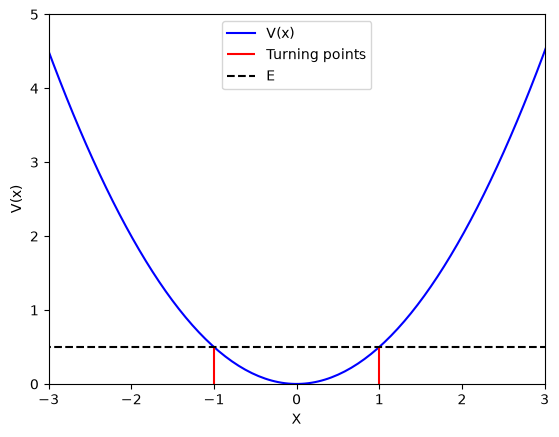

In [2]:
#set up our potentiaL

#lets start off dimensionless
hbar = 1
k = 1
m = 1
w = 1

#define the quantum energy levels
def E(n,w):
    return hbar*w*(n + 1/2)

w = np.sqrt(k/m)
x = np.linspace(-10, 10, 500)

#note the w in the function in case we change its value later
def V(x,w):
    V = (1/2)*(w**2)*(x**2)
    return V

turning_x = np.sqrt((2*E(0,w))/k)

fig,ax = plt.subplots()
ax.plot(x,V(x,w), 'b', label='V(x)')
ax.vlines([-turning_x, turning_x], 0, V(turning_x,w), 'r', label='Turning points')
ax.hlines(E(0,w), -12, 12,  'k', ls='--', label=r'E')
ax.legend()

ax.set_xlabel(r'X')
ax.set_ylabel(r'V(x)')
ax.set_ylim(0,5)
ax.set_xlim(-3,3)

## Setup
For the classical case the particle in the well is confined to regions where its $E\ge V_0$. The turning points for energy $E_0$ are shown on the above graph in red $-\sqrt{\frac{2E}{k}} \le x \le \sqrt{\frac{2E}{k}}$

However, in QM the energy levels are quantised and are seperated by $E_n = \hbar\omega(n + \frac{1}{2})$
In order to represent the possible eigenfunctions $\psi_n(x)$ we can use an analytical route using the known Hermite polynomials or a numerical route which will be discussed later on.

First we define a characteristic length $x_0 = \sqrt{\frac{\hbar}{m\omega}}$ and work with a dimensionless coordinate $a = \frac{x}{x_0}$.
This means: <br>
-The potential becomes $V(a) = \frac{1}{2}a^2$ <br>
-The exact energies are $E'_n = n + \frac{1}{2}$
-The dimensionless Hamiltonian is $\hat{H'} = \frac{\hat{H}}{{\hbar\omega}} = -\frac{1}{2}\frac{d^2}{da^2} + \frac{1}{2}a^2$

In [3]:
#implement this
x0 = np.sqrt(hbar/(m*w))
a = x/x0
#for now a = x due to our choices of constants and w

# Analytical approach
For the QHO, the eigenfunctions are known: $$\psi_n(x) = \left(\frac{1}{\sqrt{2^nn!}}\right)\left(\frac{1}{\pi^{\frac{1}{4}}x_0^{\frac{1}{2}}}\right)H_n\left(\frac{x}{x_0}\right)\exp\left(-\frac{x}{x_0}\right) $$
Thus we can use Scipy to find the Hermite polynomials and plot the wavefunctions of the first 6 energy levels.

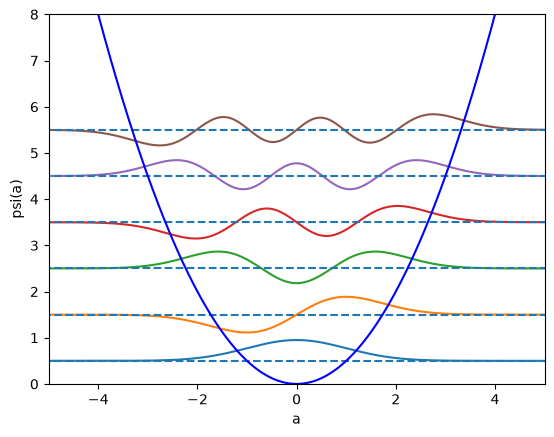

In [4]:
fig, ax = plt.subplots()
set_psi = []


for N in range(6):
    H = sc.special.eval_hermite(N, a)
    psi_n = H * (1/np.sqrt((2**N)*ma.factorial(N))) * ((1/(np.pi)**(1/4))) * np.exp(-a**2 / 2)
    set_psi.append(psi_n)

for M, psi_n in enumerate(set_psi):
    ax.plot(a, E(M,w) + 0.6*set_psi[M])
    ax.hlines([E(M,w)], -12, 12 , ls='--')

ax.plot(x,V(x,w), 'b', label='V(x)')
ax.set_xlabel(r'a')
ax.set_ylabel(r'psi(a)')
ax.set_ylim(0,8)
ax.set_xlim(-5,5)


plt.show()

We can also easily plot $|\psi|^2$:

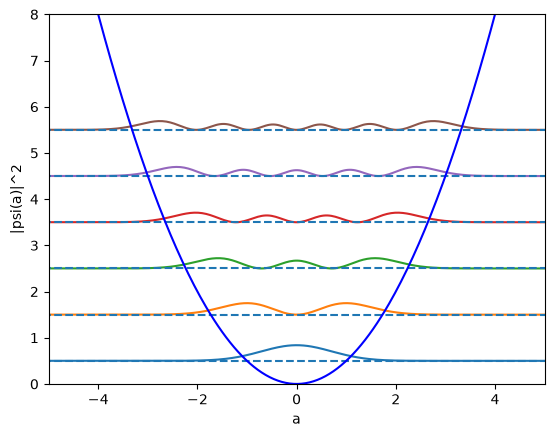

In [5]:
fig, ax = plt.subplots()

for M, psi_n in enumerate(set_psi):
    ax.plot(a, E(M,w) + 0.6*np.abs(set_psi[M])**2)
    ax.hlines([E(M,w)], -12, 12 , ls='--')

ax.plot(x,V(x,w), 'b', label='V(x)')
ax.set_xlabel(r'a')
ax.set_ylabel(r'|psi(a)|^2')
ax.set_ylim(0,8)
ax.set_xlim(-5,5)


plt.show()

# Numerical Approach
Recall the Hamiltonian in our dimensionless units: $$\hat{H}' = -\frac{1}{2}\frac{d^2}{da^2} + \frac{1}{2}a^2 (1)$$ 
To make this finite we assume the wavefunction is zero at the endpoints of the defined grid:$$\psi(a=-10),   \psi(a=10)$$ 
We can approximate the second derivative in the Hamiltonian using neighbouring points seperated by $\Delta a$ and Taylor expanding around $a_i$ $$\psi(a_i \pm \Delta a) \pm \Delta a\psi'(a_i) + \frac{(\Delta a)^2}{2}\psi''(a_i) +...$$ $$\psi''(a_i) \approx \frac{\psi(a_{i+1}) - 2\psi(a_i) + \psi(a_{i-1})}{(\Delta a)^2}$$

Applying the Hamiltonian to this:
$$-\frac{1}{2(\Delta a)^2}\psi_{i-1} + (\frac{1}{(\Delta a )^2}) + (\frac{a^2_i}{2})\psi_i + -\frac{1}{2(\Delta a )^2}\psi_{i+1} = E\psi_i$$

Now we use a 498x498 matrix (remember we fixed two values) and when diagonalised we get an approximation for the Schrodinger equation..
<bv>

$$
H'=
\begin{pmatrix}
D_1 & C & 0 & \cdots & 0 \\
C & D_2 & C & \ddots & \vdots \\
0 & C & D_3 & \ddots & 0 \\
\vdots & \ddots & \ddots & \ddots & C \\
0 & \cdots & 0 & C & D_{N-2}
\end{pmatrix},
\qquad
D_i=\frac{1}{(\Delta a)^2}+\frac{a_i^2}{2},
\qquad
C=-\frac{1}{2(\Delta a)^2}.
$$


[0.49994979 1.49974895 2.49934722]
(500, 498)


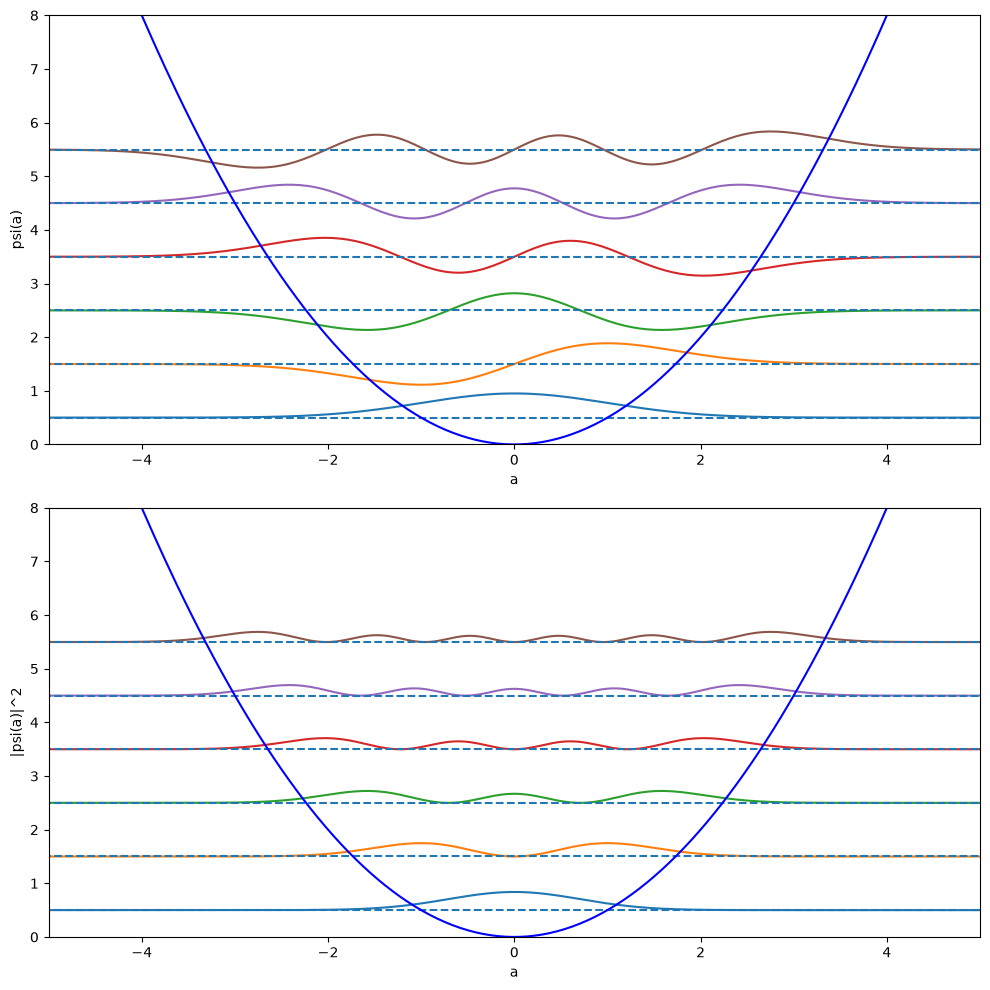

In [6]:
#implement the above
da = a[1] - a[0]
#make two arrays, one for the diagonal, one for the off diagonal
D_i = 1/(da**2) + (a[1:-1]**2)/2
C = -1/(2*(da**2))
off_diagonal = np.full((len(a[1:-1]))-1, C)

#this returns the energies and the wavefunctions so need to split it up
energies, wave_funcs = sc.linalg.eigh_tridiagonal(D_i, off_diagonal, select_range=(0,4))
wave_funcs = np.pad(wave_funcs / np.sqrt(da), ((1,1), (0,0)))
#this sqrt(da) is because scipy normalises the entries

#lets check the energies are close to the expected values
print(energies[0:3])
print(wave_funcs.shape)

#now plot as before
fig, ax = plt.subplots(2, figsize=(10,10))


for M in range(6):
    ax[1].plot(a, energies[M] + 0.6*np.abs(wave_funcs[:,M])**2)
    ax[1].hlines([energies[M]], -12, 12 , ls='--')

ax[1].plot(x,V(x,w), 'b', label='V(x)')
ax[1].set_xlabel(r'a')
ax[1].set_ylabel(r'|psi(a)|^2')
ax[1].set_ylim(0,8)
ax[1].set_xlim(-5,5)

for M in range(6):
    ax[0].plot(a, energies[M] + 0.6*(wave_funcs[:,M]))
    ax[0].hlines([energies[M]], -12, 12 , ls='--')

ax[0].plot(x,V(x,w), 'b', label='V(x)')
ax[0].set_xlabel(r'a')
ax[0].set_ylabel(r'psi(a)')
ax[0].set_ylim(0,8)
ax[0].set_xlim(-5,5)

plt.tight_layout()
plt.show()


# Comparison 
By plotting both solutions for a state $n$ on the same plot and then increasing the number of grid points in $a$, we can see if the difference shrinks as we would expect. We already saw that the energy level values from the numerical model are close to the analytical solutions, now we will analyse the wavefunctions.

ValueError: x and y must have same first dimension, but have shapes (1000,) and (500,)

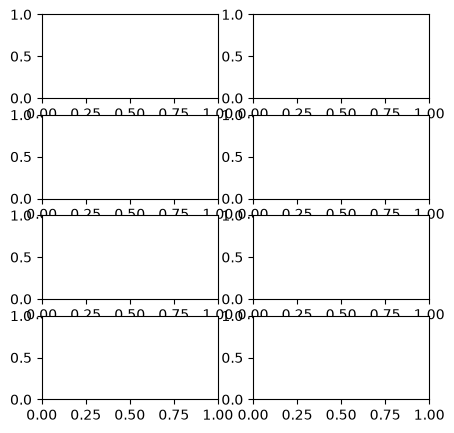

In [30]:
for N in [10,100,500,1000]:
    a = np.linspace(-10, 10, N)
    da = a[1] - a[0]
    



fig,ax = plt.subplots(4,2, figsize=(5,5))

ax[0,0].plot(a, E(0,w) + 0.8*(wave_funcs[:,0]))
ax[0,0].plot(a, E(0,w) + 0.8*(set_psi[0]))


ax[0,0].set_xlabel(r'a')
ax[0,0].set_ylabel(r'psi(a)')
ax[0,0].set_ylim(0,2)
ax[0,0].set_xlim(-3,3)

plt.tight_layout()
plt.show()